<a href="https://colab.research.google.com/github/julienessan/Gomycode_Cours_Data_Sciences/blob/main/Checkpoint_corriger_surapprentissage.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Checkpoint: Identifier et corriger le surapprentissage d'un CNN sur CIFAR-10

# Objectif:
Identifier et corriger le surapprentissage dans un CNN en utilisant des stratégies de régularisation.

## 1. Imports et données

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import f1_score

(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
x_train = x_train / 255.0
x_test = x_test / 255.0
y_train = y_train.ravel()
y_test = y_test.ravel()

print("Train :", x_train.shape, "| Test :", x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1580s 9us/step
Train : (50000, 32, 32, 3) | Test : (10000, 32, 32, 3)


Je sépare les données en trois parties :
- **entraînement** : 90 % de `x_train` ;
- **validation** : 10 % de `x_train`, via `validation_split`, pour suivre le surapprentissage à chaque époque ;
- **test** : les 10 000 images de `x_test`, utilisées une seule fois à la fin pour les scores finaux.

In [2]:
EPOQUES = 20
BATCH = 64
TAUX_APPRENTISSAGE = 0.001
VALIDATION = 0.1

def compiler(model):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=TAUX_APPRENTISSAGE),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

def nb_param_entrainables(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))

params = {}   # nombre de paramètres entraînables de chaque modèle

def entrainer(model):
    return model.fit(x_train, y_train, epochs=EPOQUES, batch_size=BATCH,
                     validation_split=VALIDATION)

## 2. Baseline : un CNN qui surapprend

In [3]:
keras.utils.set_random_seed(42)

baseline = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, 3, padding="same", activation="relu", name="bloc1_conv1"),
    layers.Conv2D(32, 3, padding="same", activation="relu", name="bloc1_conv2"),
    layers.MaxPooling2D(name="bloc1_pool"),
    layers.Conv2D(64, 3, padding="same", activation="relu", name="bloc2_conv1"),
    layers.Conv2D(64, 3, padding="same", activation="relu", name="bloc2_conv2"),
    layers.MaxPooling2D(name="bloc2_pool"),
    layers.Conv2D(128, 3, padding="same", activation="relu", name="bloc3_conv1"),
    layers.Conv2D(128, 3, padding="same", activation="relu", name="bloc3_conv2"),
    layers.MaxPooling2D(name="bloc3_pool"),
    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.Dense(10, activation="softmax"),
], name="baseline")

compiler(baseline)
baseline.summary()
params["Baseline"] = nb_param_entrainables(baseline)
hist_base = entrainer(baseline)

Model: "baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bloc1_conv1 (Conv2D)            │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bloc1_conv2 (Conv2D)            │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bloc1_pool (MaxPooling2D)       │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bloc2_conv1 (Conv2D)            │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bloc2_conv2 (Conv2D)            │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bloc2_pool (MaxPooling2D)       │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bloc3_conv1 (Conv2D)            │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bloc3_conv2 (Conv2D)            │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bloc3_pool (MaxPooling2D)       │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,341,226 (5.12 MB)

 Trainable params: 1,341,226 (5.12 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 25s 21ms/step - accuracy: 0.4451 - loss: 1.5025 - val_accuracy: 0.5412 - val_loss: 1.2558
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.6404 - loss: 1.0146 - val_accuracy: 0.6938 - val_loss: 0.8887
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.7192 - loss: 0.7934 - val_accuracy: 0.7296 - val_loss: 0.7806
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.7742 - loss: 0.6431 - val_accuracy: 0.7434 - val_loss: 0.7567
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8142 - loss: 0.5254 - val_accuracy: 0.7522 - val_loss: 0.7530
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8443 - loss: 0.4413 - val_accuracy: 0.7372 - val_loss: 0.9122
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8640 - loss: 0.3844 - val_accuracy: 0.7542 - val_loss: 0.8733
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8911 - loss: 0.3086 - val_accuracy: 

### Signes de surapprentissage

On cherche les trois signes de l'énoncé :
- une précision d'entraînement élevée ;
- une précision de validation nettement plus faible ;
- des courbes de perte qui divergent : la perte d'entraînement continue de baisser pendant que la perte de validation remonte.

Précision train finale      : 96.81%
Précision validation finale : 75.76%
Écart                       : 21.0 points
val_loss minimale à l'époque 5 (0.753), finale : 1.761


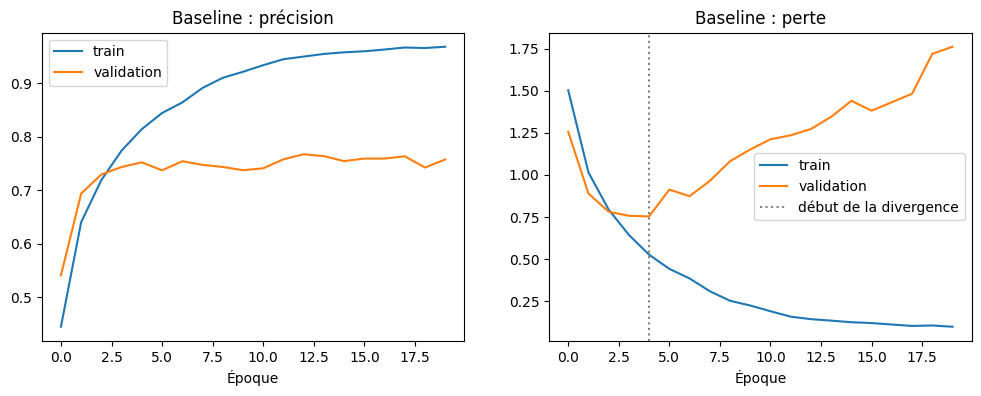

In [4]:
h = hist_base.history
ep_min = int(np.argmin(h["val_loss"])) + 1

print(f"Précision train finale      : {h['accuracy'][-1]:.2%}")
print(f"Précision validation finale : {h['val_accuracy'][-1]:.2%}")
print(f"Écart                       : {(h['accuracy'][-1] - h['val_accuracy'][-1]) * 100:.1f} points")
print(f"val_loss minimale à l'époque {ep_min} ({min(h['val_loss']):.3f}), finale : {h['val_loss'][-1]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["accuracy"], label="train"); ax[0].plot(h["val_accuracy"], label="validation")
ax[0].set_title("Baseline : précision"); ax[0].set_xlabel("Époque"); ax[0].legend()
ax[1].plot(h["loss"], label="train"); ax[1].plot(h["val_loss"], label="validation")
ax[1].axvline(ep_min - 1, color="gray", linestyle=":", label="début de la divergence")
ax[1].set_title("Baseline : perte"); ax[1].set_xlabel("Époque"); ax[1].legend()
plt.show()

## 3. Stratégies de régularisation

### 3.a Augmentation des données

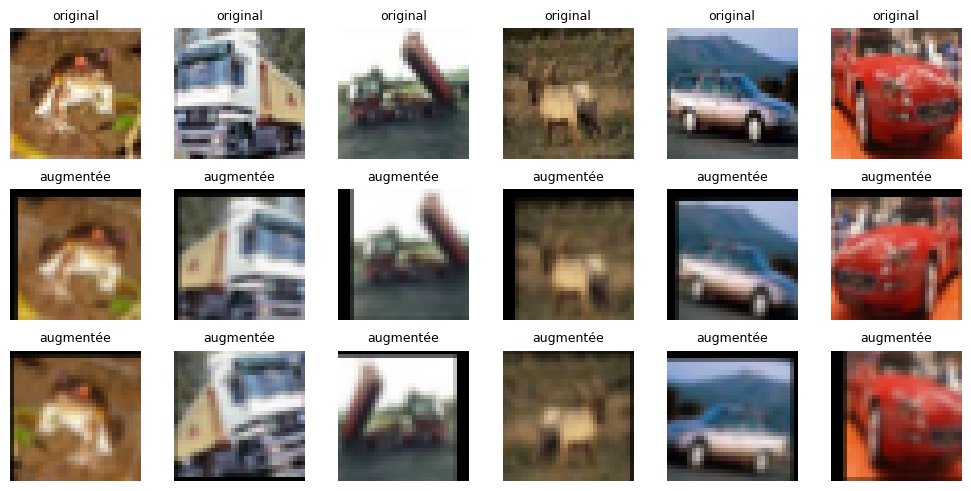

In [5]:
def couches_augmentation():
    return [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),
        layers.RandomTranslation(0.125, 0.125, fill_mode="constant"),
    ]

# visualisation : 1re ligne = originales, lignes suivantes = augmentées
aug = keras.Sequential(couches_augmentation())
exemples = x_train[:6]
plt.figure(figsize=(10, 5))
for ligne in range(3):
    images = exemples if ligne == 0 else aug(exemples, training=True).numpy()
    for i in range(6):
        plt.subplot(3, 6, ligne * 6 + i + 1)
        plt.imshow(np.clip(images[i], 0, 1)); plt.axis("off")
        plt.title("original" if ligne == 0 else "augmentée", fontsize=9)
plt.tight_layout(); plt.show()

### 3.b Modèle régularisé : augmentation + Batch Normalization + Dropout

In [6]:
def conv_bn(filtres):
    return [layers.Conv2D(filtres, 3, padding="same"),
            layers.BatchNormalization(),
            layers.Activation("relu")]

keras.utils.set_random_seed(42)

regularise = keras.Sequential(
    [keras.Input(shape=(32, 32, 3))]
    + couches_augmentation()
    + conv_bn(32) + conv_bn(32) + [layers.MaxPooling2D(), layers.Dropout(0.2)]
    + conv_bn(64) + conv_bn(64) + [layers.MaxPooling2D(), layers.Dropout(0.3)]
    + conv_bn(128) + conv_bn(128) + [layers.MaxPooling2D(), layers.Dropout(0.4)]
    + [layers.Flatten(),
       layers.Dense(512, activation="relu"),
       layers.Dropout(0.5),
       layers.Dense(10, activation="softmax")],
    name="regularise",
)

compiler(regularise)
regularise.summary()
params["Régularisé"] = nb_param_entrainables(regularise)
hist_reg = entrainer(regularise)

Model: "regularise"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 32, 32, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_1            │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,343,018 (5.12 MB)

 Trainable params: 1,342,122 (5.12 MB)

 Non-trainable params: 896 (3.50 KB)

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 22s 21ms/step - accuracy: 0.3006 - loss: 1.9094 - val_accuracy: 0.4482 - val_loss: 1.4793
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.4204 - loss: 1.5763 - val_accuracy: 0.4040 - val_loss: 1.8944
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 20s 20ms/step - accuracy: 0.4827 - loss: 1.4307 - val_accuracy: 0.4930 - val_loss: 1.4718
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.5241 - loss: 1.3255 - val_accuracy: 0.5424 - val_loss: 1.3057
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.5641 - loss: 1.2281 - val_accuracy: 0.5938 - val_loss: 1.2724
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.5889 - loss: 1.1599 - val_accuracy: 0.5510 - val_loss: 1.3028
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.6208 - loss: 1.0864 - val_accuracy: 0.6766 - val_loss: 0.9443
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.6396 - loss: 1.0378 - 

### 3.c Modèle gelé : couches inférieures figées, couches supérieures réentraînées


In [7]:
couches_basses = [l for l in baseline.layers if l.name.startswith(("bloc1", "bloc2"))]
# remarque : ces couches sont partagées avec la baseline. Les geler ne change pas
# ses prédictions, cela empêche seulement leurs poids d'être modifiés.
for couche in couches_basses:
    couche.trainable = False          # gel des couches inférieures

print("Couches gelées :", [l.name for l in couches_basses])

keras.utils.set_random_seed(42)

gele = keras.Sequential(
    [keras.Input(shape=(32, 32, 3))]
    + couches_augmentation()
    + couches_basses                                   # blocs 1-2 de la baseline (figés)
    + conv_bn(128) + conv_bn(128)                      # nouveau bloc 3 (entraîné)
    + [layers.MaxPooling2D(), layers.Dropout(0.4),
       layers.Flatten(),
       layers.Dense(256, activation="relu"),
       layers.Dropout(0.5),
       layers.Dense(10, activation="softmax")],
    name="gele",
)

compiler(gele)
gele.summary()
params["Gelé"] = nb_param_entrainables(gele)
hist_gele = entrainer(gele)

Couches gelées : ['bloc1_conv1', 'bloc1_conv2', 'bloc1_pool', 'bloc2_conv1', 'bloc2_conv2', 'bloc2_pool']


Model: "gele"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_2 (RandomFlip)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_2               │ (None, 32, 32, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_2            │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bloc1_conv1 (Conv2D)            │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bloc1_conv2 (Conv2D)            │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bloc1_pool (MaxPooling2D)       │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bloc2_conv1 (Conv2D)            │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bloc2_conv2 (Conv2D)            │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bloc2_pool (MaxPooling2D)       │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 815,146 (3.11 MB)

 Trainable params: 749,066 (2.86 MB)

 Non-trainable params: 66,080 (258.12 KB)

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.4276 - loss: 1.5927 - val_accuracy: 0.5194 - val_loss: 1.4582
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.5399 - loss: 1.2943 - val_accuracy: 0.5924 - val_loss: 1.2151
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - accuracy: 0.5769 - loss: 1.2089 - val_accuracy: 0.5856 - val_loss: 1.2677
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.5997 - loss: 1.1446 - val_accuracy: 0.6492 - val_loss: 1.0161
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.6157 - loss: 1.1059 - val_accuracy: 0.6754 - val_loss: 0.9797
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.6284 - loss: 1.0725 - val_accuracy: 0.6760 - val_loss: 0.9549
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.6429 - loss: 1.0375 - val_accuracy: 0.6914 - val_loss: 0.9363
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.6552 - loss: 1.0102 - val_ac

## 4. Comparaison des trois modèles

### 4.a Courbes train vs validation

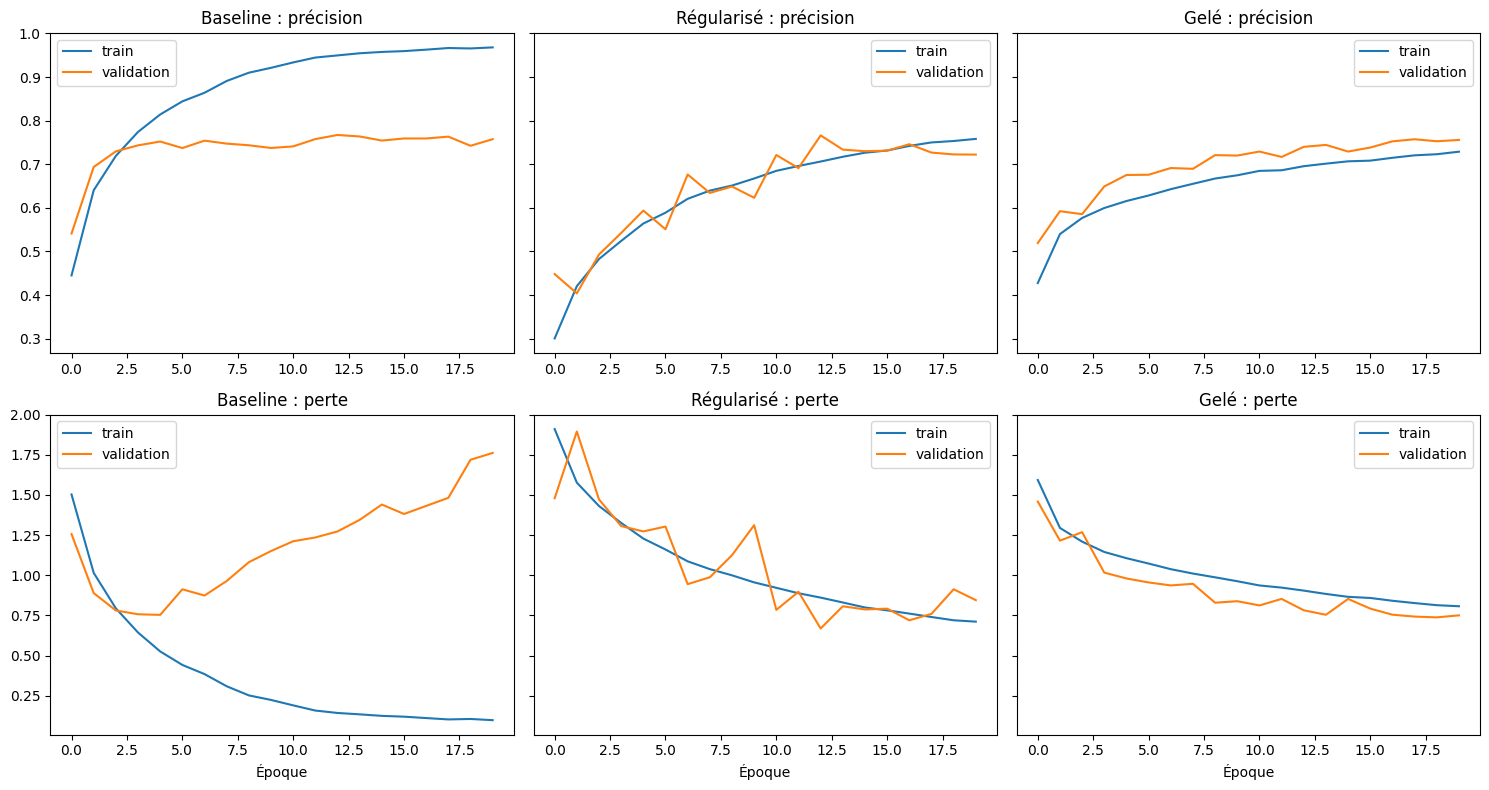

In [8]:
historiques = {"Baseline": hist_base.history,
               "Régularisé": hist_reg.history,
               "Gelé": hist_gele.history}

fig, ax = plt.subplots(2, 3, figsize=(15, 8), sharey="row")
for j, (nom, h) in enumerate(historiques.items()):
    ax[0, j].plot(h["accuracy"], label="train")
    ax[0, j].plot(h["val_accuracy"], label="validation")
    ax[0, j].set_title(f"{nom} : précision"); ax[0, j].legend()
    ax[1, j].plot(h["loss"], label="train")
    ax[1, j].plot(h["val_loss"], label="validation")
    ax[1, j].set_title(f"{nom} : perte"); ax[1, j].set_xlabel("Époque"); ax[1, j].legend()
plt.tight_layout(); plt.show()

### 4.b Indicateurs finaux

In [9]:
modeles = {"Baseline": baseline, "Régularisé": regularise, "Gelé": gele}

print(f"{'':<12}{'Préc. train':>12}{'Préc. val':>11}{'Écart':>9}{'Préc. test':>12}{'F1 test':>9}{'Param. entraînables':>22}")
for nom, model in modeles.items():
    h = historiques[nom]
    y_pred = model.predict(x_test, verbose=0).argmax(axis=1)
    acc_test = np.mean(y_pred == y_test)
    f1 = f1_score(y_test, y_pred, average="macro")
    ecart = h["accuracy"][-1] - h["val_accuracy"][-1]
    print(f"{nom:<12}{h['accuracy'][-1]:>12.2%}{h['val_accuracy'][-1]:>11.2%}{ecart * 100:>8.1f}p"
          f"{acc_test:>12.2%}{f1:>9.3f}{params[nom]:>22,}")

             Préc. train  Préc. val    Écart  Préc. test  F1 test   Param. entraînables
Baseline          96.81%     75.76%    21.0p      74.92%    0.745             1,341,226
Régularisé        75.82%     72.22%     3.6p      71.14%    0.698             1,342,122
Gelé              72.89%     75.58%    -2.7p      73.68%    0.725               749,066


## 5. Analyse

La baseline montre clairement du surapprentissage : 96,8 % de précision en entraînement contre 75,8 % en validation, soit 21 points d’écart. Les deux stratégies de régularisation ont presque supprimé cet écart. Il tombe à 3,6 points pour le modèle régularisé (augmentation, Batch Normalization et dropout), et le modèle gelé fait même légèrement mieux en validation qu’en entraînement, ce qui s’explique par le fait que le dropout et l’augmentation ne s’appliquent qu’à l’entraînement.